In [1]:
import pandas as pd
import os
from typing import Tuple, Set, Dict
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)

In [2]:
CSV_PROCESSED_DATA_FOLDER = "../../dataset/identify-iot-devices-and-events-based-on-packet-length-from-encrypted-traffic/processed-data/from-csv"
CSV_PROCESSED_DATA_FILE = CSV_PROCESSED_DATA_FOLDER +  "/preprocessed_features.csv"

# Stage 1 - IoT and non-IoT identification

In [3]:
df = pd.read_csv(os.path.join(CSV_PROCESSED_DATA_FILE))
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 906532 entries, 0 to 906531
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   device_mac          906532 non-null  str    
 1   timestamp           906532 non-null  int64  
 2   mean_packet_length  906532 non-null  float64
 3   std_packet_length   906532 non-null  float64
 4   total_bytes         906532 non-null  int64  
 5   packet_count        906532 non-null  int64  
 6   device_name         906532 non-null  str    
 7   is_iot              906532 non-null  int64  
dtypes: float64(2), int64(4), str(2)
memory usage: 55.3 MB


None

,device_mac,timestamp,mean_packet_length,std_packet_length,total_bytes,packet_count,device_name,is_iot
0,00:16:6c:ab:6b:88,1474552807,398.312500,281.345036,6373,16,Samsung SmartCam,1
1,00:16:6c:ab:6b:88,1474552808,301.600000,483.608578,4524,15,Samsung SmartCam,1
2,00:16:6c:ab:6b:88,1474552822,127.000000,86.267027,254,2,Samsung SmartCam,1
3,00:16:6c:ab:6b:88,1474552837,477.285714,26.694034,3341,7,Samsung SmartCam,1
4,00:16:6c:ab:6b:88,1474552852,127.000000,86.267027,254,2,Samsung SmartCam,1


In [4]:
features_columns = ["timestamp", "mean_packet_length", "std_packet_length", "total_bytes"]
packet_feature_columns = ["mean_packet_length","std_packet_length","total_bytes"]
label_column = "is_iot"

In [5]:
stage1_data = df[features_columns + [label_column]]
stage1_features = df[features_columns]
stage1_label = df[label_column]

display(stage1_data.head())

,timestamp,mean_packet_length,std_packet_length,total_bytes,is_iot
0,1474552807,398.312500,281.345036,6373,1
1,1474552808,301.600000,483.608578,4524,1
2,1474552822,127.000000,86.267027,254,1
3,1474552837,477.285714,26.694034,3341,1
4,1474552852,127.000000,86.267027,254,1


## EDA

In [6]:
stage1_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 906532 entries, 0 to 906531
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   timestamp           906532 non-null  int64  
 1   mean_packet_length  906532 non-null  float64
 2   std_packet_length   906532 non-null  float64
 3   total_bytes         906532 non-null  int64  
 4   is_iot              906532 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 34.6 MB


In [7]:
print("Missing values:\n", stage1_data.isna().sum())

Missing values:
 timestamp             0
mean_packet_length    0
std_packet_length     0
total_bytes           0
is_iot                0
dtype: int64


In [8]:
print("Unique labels:")
print(stage1_data[label_column].unique())

print("\nNumber of unique labels:")
print(stage1_data[label_column].nunique(dropna=False))

label_counts = stage1_data[label_column].value_counts(
    dropna=False
)

label_percentages = (
    stage1_data[label_column]
    .value_counts(
        normalize=True,
        dropna=False,
    )
    .mul(100)
)

class_distribution = pd.DataFrame({
    "count": label_counts,
    "percentage": label_percentages,
})

print("\nClass distribution:")
display(class_distribution)

Unique labels:
[1 0]

Number of unique labels:
2

Class distribution:


,count,percentage
is_iot,,
1,813186,89.702956
0,93346,10.297044


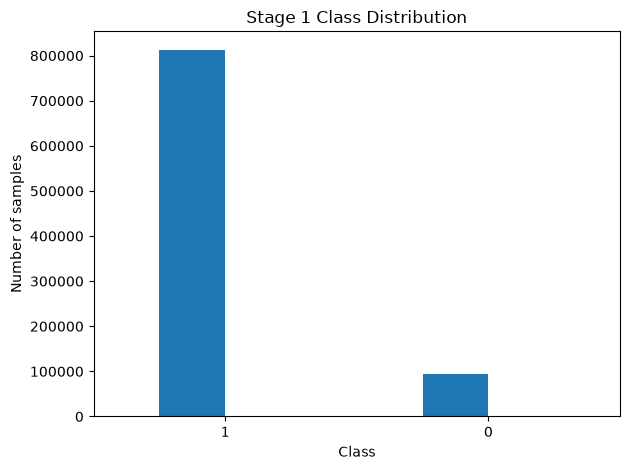

In [9]:
class_distribution.plot(kind="bar", title="Class Distribution", legend=False)
plt.title("Stage 1 Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
overall_summary = (
    stage1_data[packet_feature_columns]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
    .T
)

display(overall_summary)

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
mean_packet_length,906532.0,190.292845,169.215162,46.0,54.0,66.0,72.5,96.647059,145.5,220.000000,418.000000,477.285714,922.699091,1.514000e+03
std_packet_length,906532.0,82.365899,132.724931,0.0,0.0,0.0,0.0,4.242641,45.0,90.509668,157.770373,446.538369,643.312206,1.030255e+03
total_bytes,906532.0,1818.632346,10940.280969,92.0,128.0,149.0,162.0,244.000000,440.0,963.000000,3341.000000,4341.000000,26514.690000,4.354838e+06


In [11]:
class_summary = (
    stage1_data
    .groupby(label_column, dropna=False)[packet_feature_columns]
    .agg([
        "count",
        "mean",
        "std",
        "median",
        "min",
        "max",
    ])
)

print(class_summary)

       mean_packet_length                                               \
                    count        mean         std median   min     max   
is_iot                                                                   
0                   93346  169.353495  170.279461  107.0  46.0  1514.0   
1                  813186  192.696483  168.926677  145.5  54.0  1514.0   

       std_packet_length                                                       \
                   count        mean         std     median  min          max   
is_iot                                                                          
0                  93346  132.783276  165.293256  64.935866  0.0  1030.254580   
1                 813186   76.578465  127.186897  45.000000  0.0  1021.769299   

       total_bytes                                                  
             count         mean           std median  min      max  
is_iot                                                              
0            933

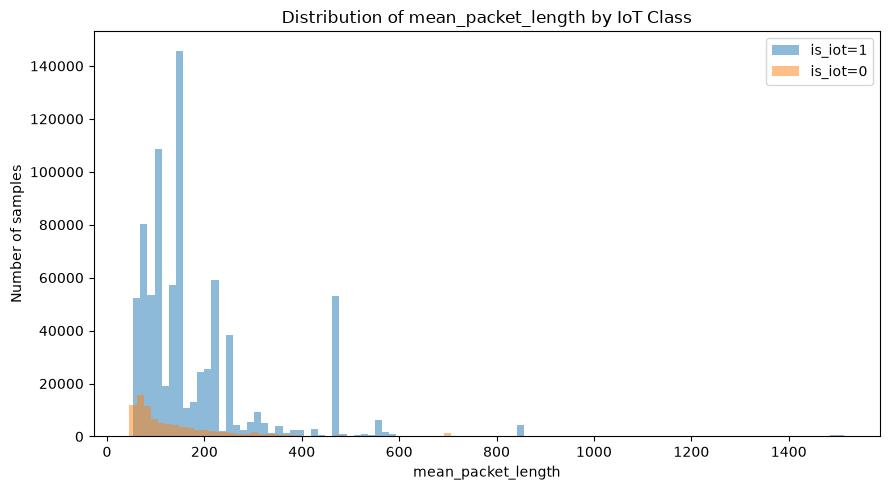

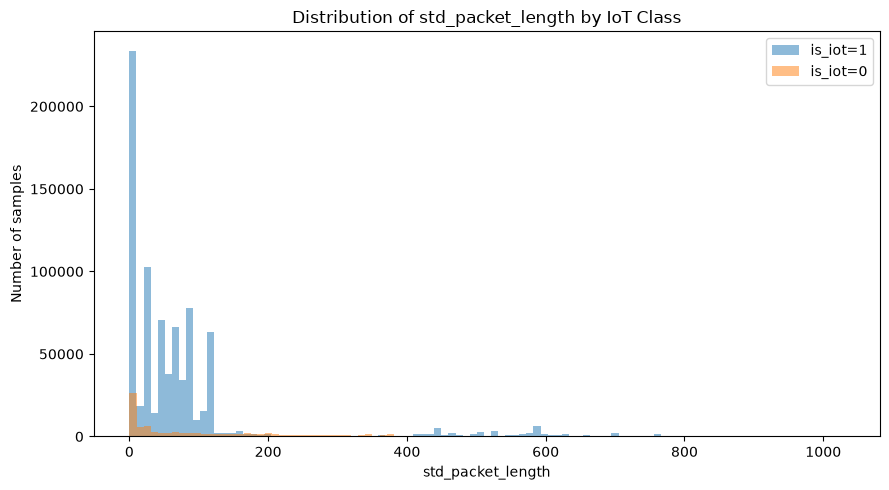

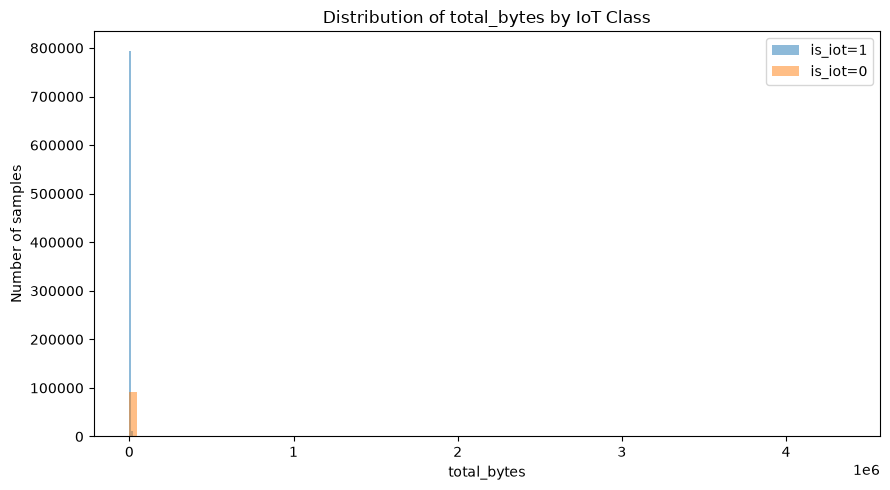

In [12]:
class_values = (
    stage1_data[label_column]
    .dropna()
    .unique()
)

for feature in packet_feature_columns:
    plt.figure(figsize=(9, 5))

    for class_value in class_values:
        class_data = stage1_data.loc[
            stage1_data[label_column] == class_value,
            feature,
        ].dropna()

        plt.hist(
            class_data,
            bins=100,
            alpha=0.5,
            label=f"{label_column}={class_value}",
        )

    plt.title(f"Distribution of {feature} by IoT Class")
    plt.xlabel(feature)
    plt.ylabel("Number of samples")
    plt.legend()
    plt.tight_layout()
    plt.show()

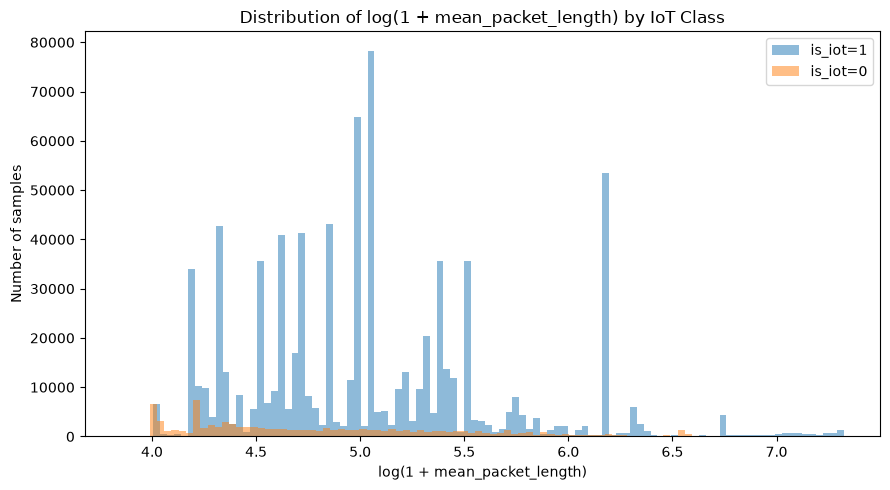

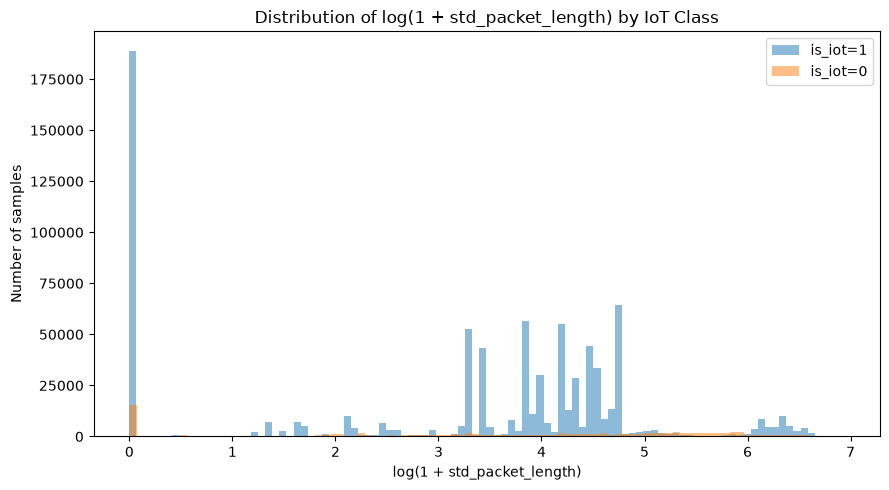

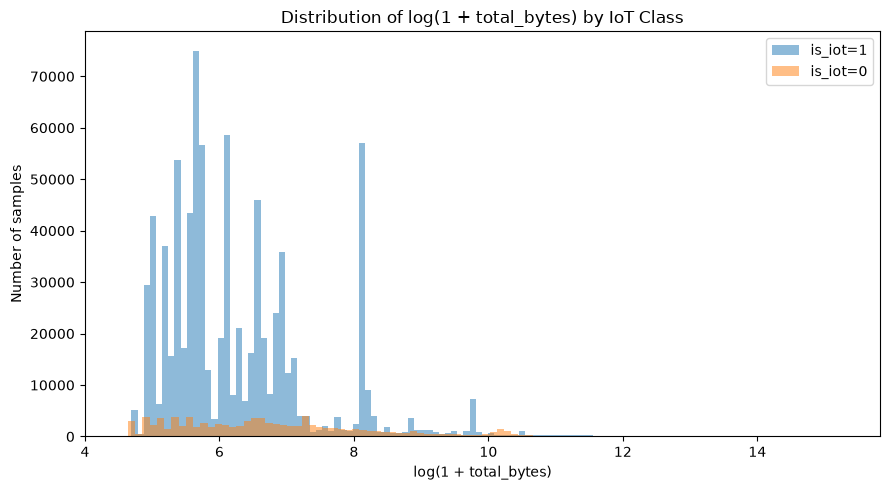

In [13]:
for feature in packet_feature_columns:
    plt.figure(figsize=(9, 5))

    for class_value in class_values:
        class_data = stage1_data.loc[
            stage1_data[label_column] == class_value,
            feature,
        ].dropna()

        class_data = class_data[class_data >= 0]

        plt.hist(
            np.log1p(class_data),
            bins=100,
            alpha=0.5,
            label=f"{label_column}={class_value}",
        )

    plt.title(
        f"Distribution of log(1 + {feature}) by IoT Class"
    )
    plt.xlabel(f"log(1 + {feature})")
    plt.ylabel("Number of samples")
    plt.legend()
    plt.tight_layout()
    plt.show()

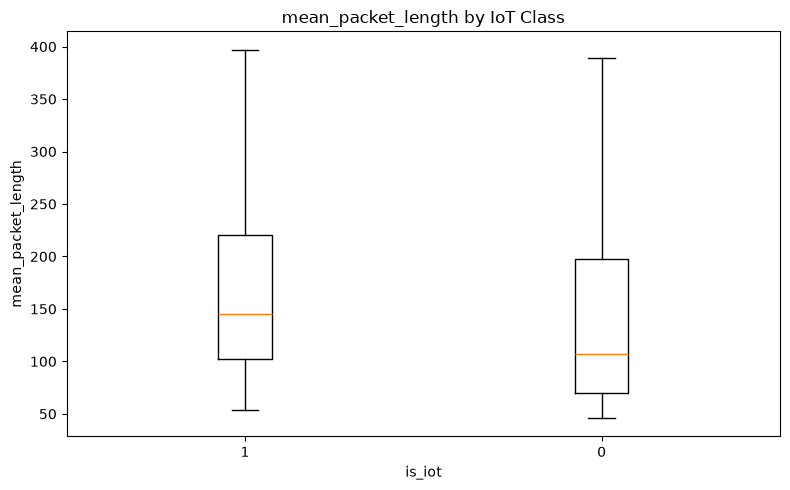

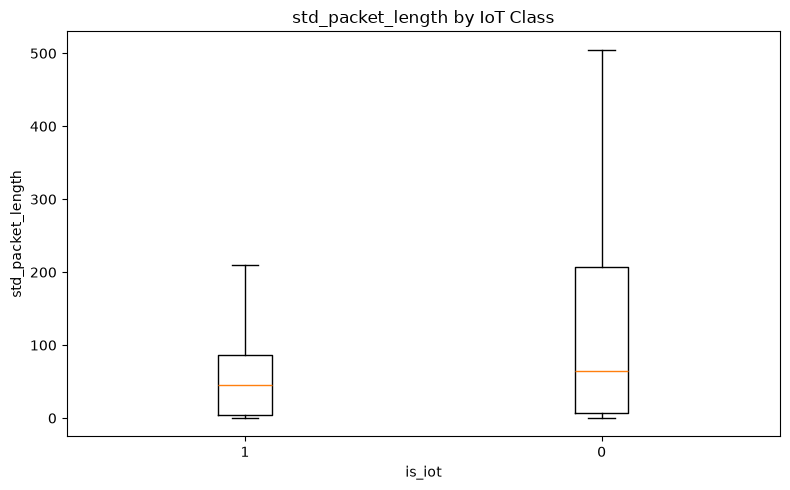

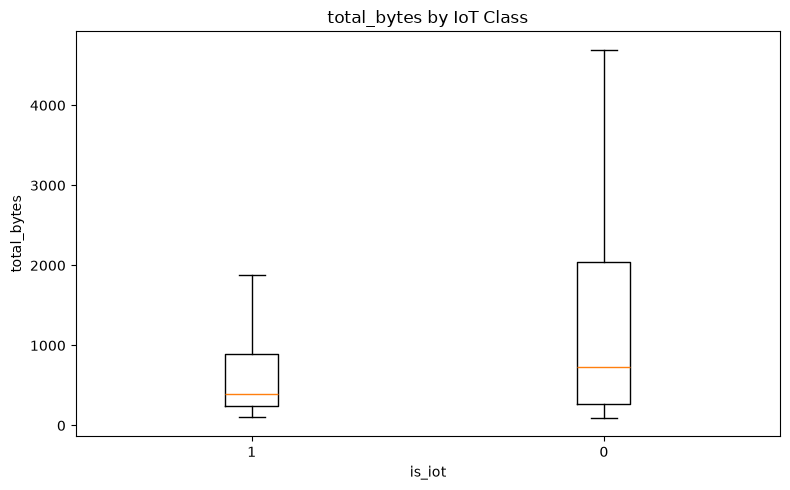

In [14]:
for feature in packet_feature_columns:
    class_groups = []
    class_labels = []

    for class_value in class_values:
        values = stage1_data.loc[
            stage1_data[label_column] == class_value,
            feature,
        ].dropna()

        class_groups.append(values.to_numpy())
        class_labels.append(str(class_value))

    plt.figure(figsize=(8, 5))

    plt.boxplot(
        class_groups,
        tick_labels=class_labels,
        showfliers=False,
    )

    plt.title(f"{feature} by IoT Class")
    plt.xlabel(label_column)
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

In [15]:
pearson_correlation = (
    stage1_data[packet_feature_columns]
    .corr(method="pearson")
)

print("Pearson correlation:")
display(pearson_correlation)

Pearson correlation:


,mean_packet_length,std_packet_length,total_bytes
mean_packet_length,1.000000,0.561358,0.371974
std_packet_length,0.561358,1.000000,0.206818
total_bytes,0.371974,0.206818,1.000000


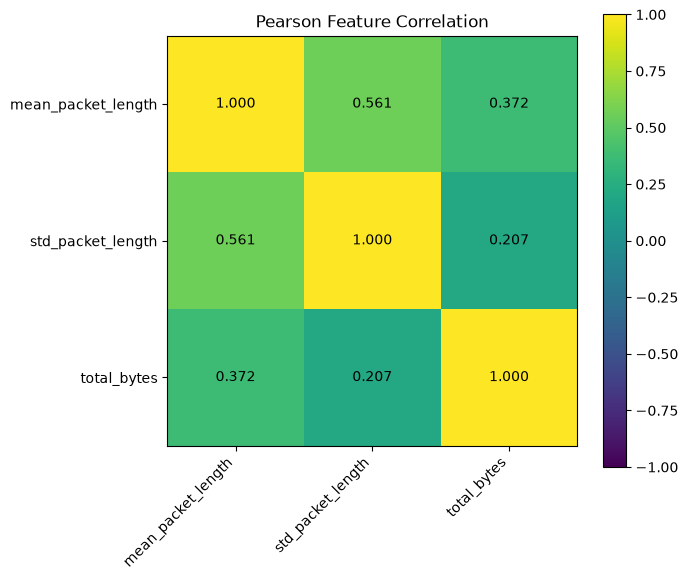

In [16]:
plt.figure(figsize=(7, 6))

image = plt.imshow(
    pearson_correlation,
    vmin=-1,
    vmax=1,
)

plt.colorbar(image)

plt.xticks(
    range(len(packet_feature_columns)),
    packet_feature_columns,
    rotation=45,
    ha="right",
)

plt.yticks(
    range(len(packet_feature_columns)),
    packet_feature_columns,
)

for row_index in range(len(packet_feature_columns)):
    for column_index in range(len(packet_feature_columns)):
        plt.text(
            column_index,
            row_index,
            f"{pearson_correlation.iloc[row_index, column_index]:.3f}",
            ha="center",
            va="center",
        )

plt.title("Pearson Feature Correlation")
plt.tight_layout()
plt.show()

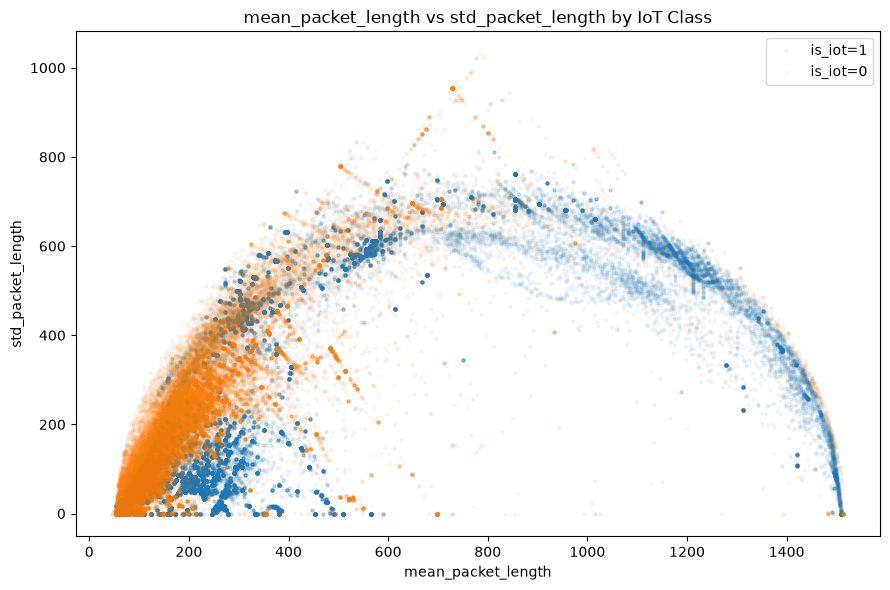

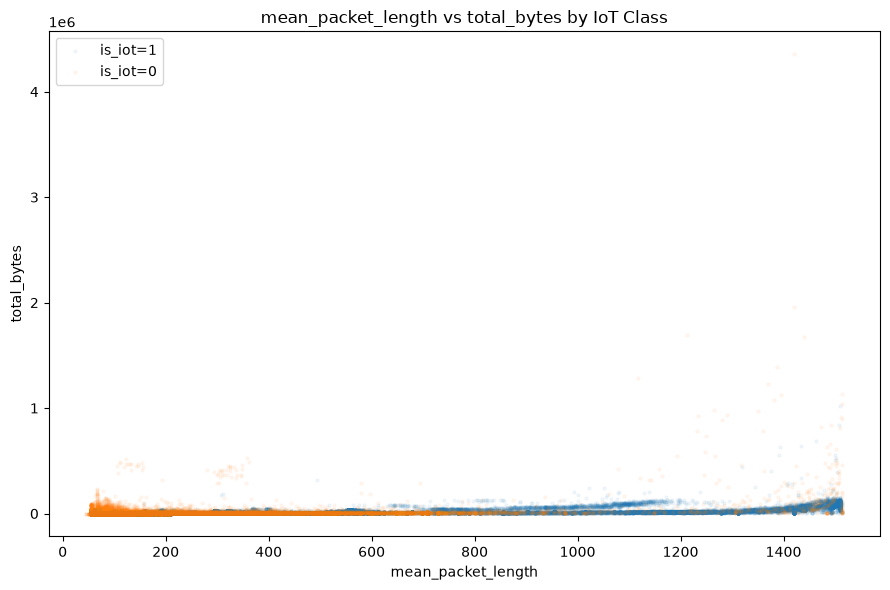

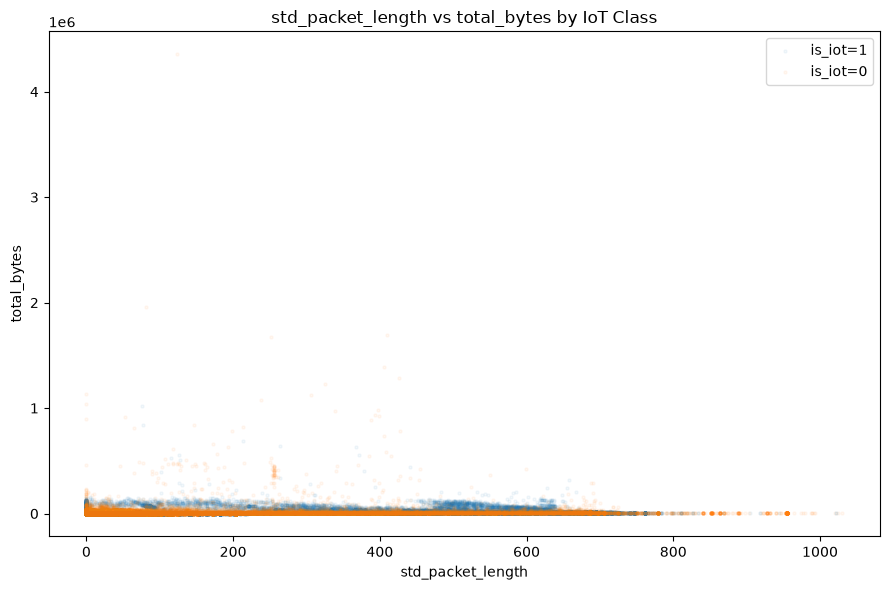

In [17]:
feature_pairs = [
    (
        "mean_packet_length",
        "std_packet_length",
    ),
    (
        "mean_packet_length",
        "total_bytes",
    ),
    (
        "std_packet_length",
        "total_bytes",
    ),
]

for x_feature, y_feature in feature_pairs:
    plt.figure(figsize=(9, 6))

    for class_value in class_values:
        class_data = stage1_data[
            stage1_data[label_column] == class_value
        ]

        plt.scatter(
            class_data[x_feature],
            class_data[y_feature],
            alpha=0.05,
            s=5,
            rasterized=True,
            label=f"{label_column}={class_value}",
        )

    plt.title(
        f"{x_feature} vs {y_feature} by IoT Class"
    )
    plt.xlabel(x_feature)
    plt.ylabel(y_feature)
    plt.legend()
    plt.tight_layout()
    plt.show()

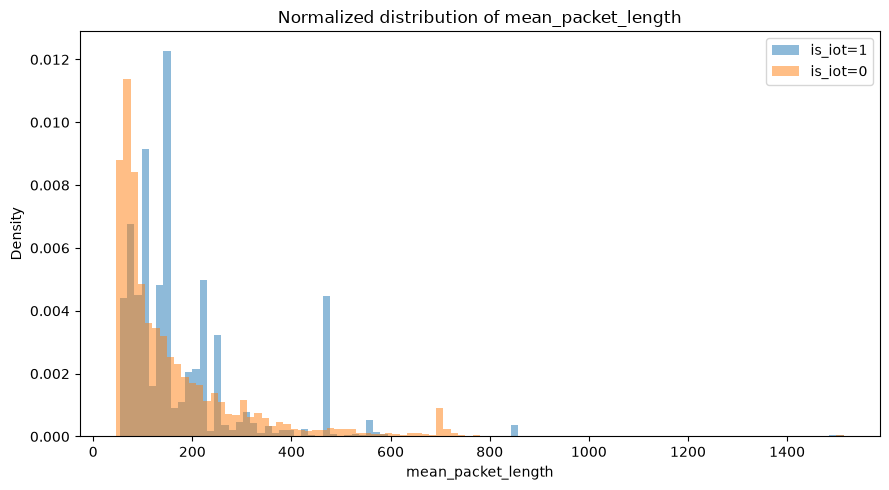

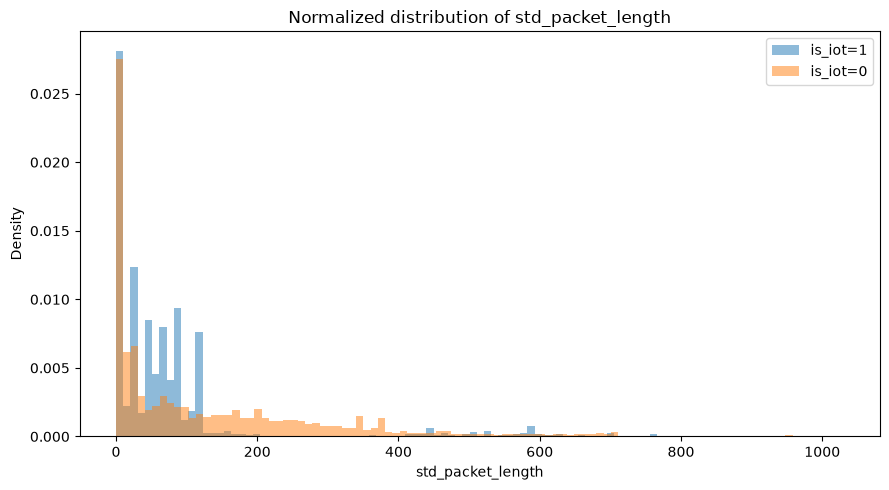

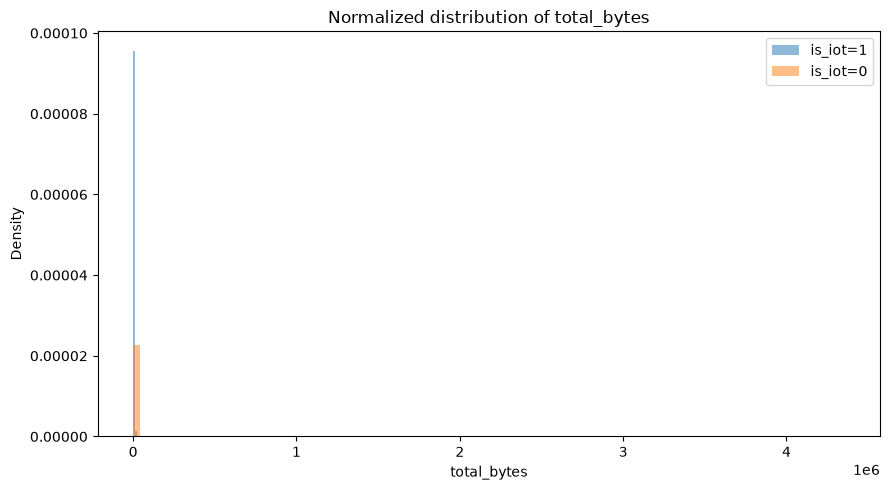

In [18]:
for feature in packet_feature_columns:
    plt.figure(figsize=(9, 5))

    for class_value in class_values:
        values = stage1_data.loc[
            stage1_data[label_column] == class_value,
            feature,
        ]

        plt.hist(
            values,
            bins=100,
            density=True,
            alpha=0.5,
            label=f"is_iot={class_value}",
        )

    plt.title(f"Normalized distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

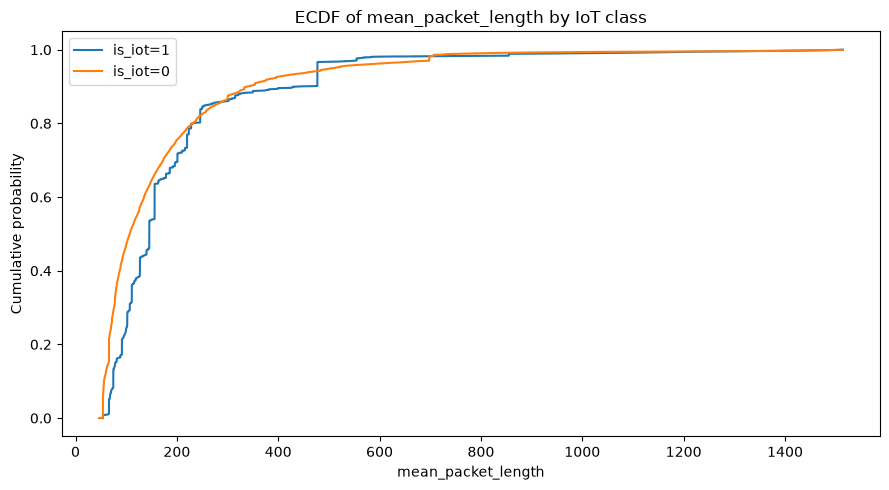

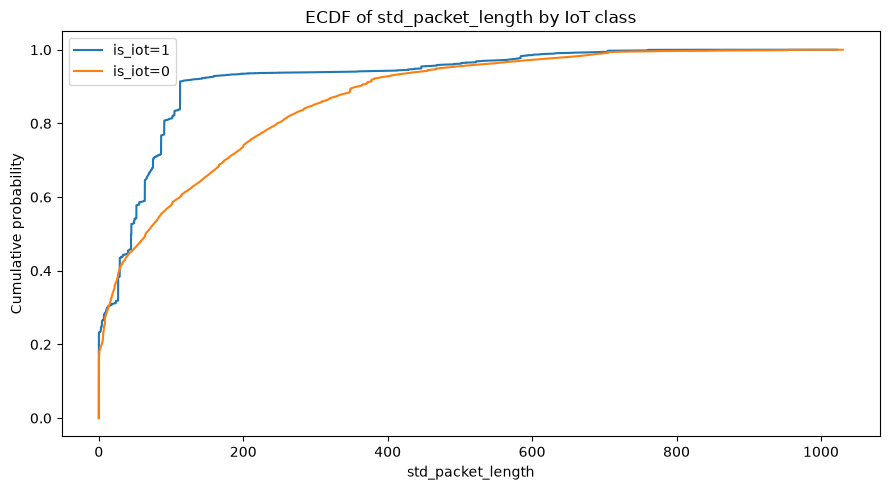

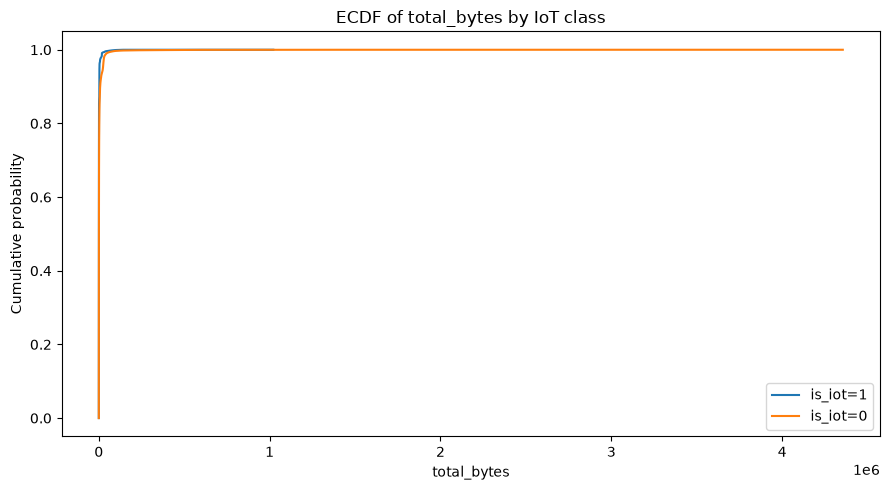

In [19]:
for feature in packet_feature_columns:
    plt.figure(figsize=(9, 5))

    for class_value in class_values:
        values = (
            stage1_data.loc[
                stage1_data[label_column] == class_value,
                feature,
            ]
            .sort_values()
            .to_numpy()
        )

        cumulative_probability = (
            np.arange(1, len(values) + 1) / len(values)
        )

        plt.plot(
            values,
            cumulative_probability,
            label=f"is_iot={class_value}",
        )

    plt.title(f"ECDF of {feature} by IoT class")
    plt.xlabel(feature)
    plt.ylabel("Cumulative probability")
    plt.legend()
    plt.tight_layout()
    plt.show()

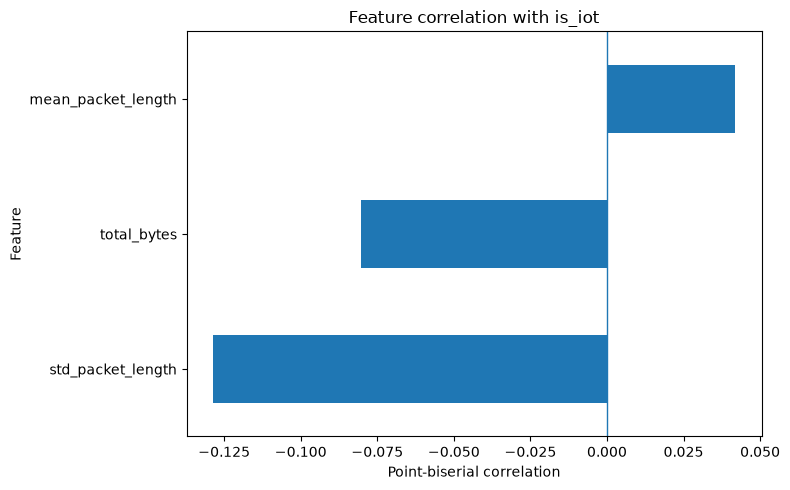

std_packet_length    -0.128701
total_bytes          -0.080370
mean_packet_length    0.041925
Name: is_iot, dtype: float64


In [20]:
feature_label_correlations = (
    stage1_data[
        packet_feature_columns + [label_column]
    ]
    .corr(method="pearson")[label_column]
    .drop(label_column)
    .sort_values()
)

plt.figure(figsize=(8, 5))

feature_label_correlations.plot(kind="barh")

plt.axvline(0, linewidth=1)
plt.title("Feature correlation with is_iot")
plt.xlabel("Point-biserial correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(feature_label_correlations)

- 2 type of splits has been done for evaluation and testing
    - Randomly divide the dataset into training and test sets (seed is not provided) - 75/25
    - Chronologically divide the dataset into training and test sets - 75/25
- Training is resampled with the following algorithm to combat imbalance in the dataset:
    - SMOTE
    - Random Under Sampling
    - Balance Cascade
- 5 classifier has been trained and evaluated in the paper
    - kNN - `k = 5`
    - Random Forest
    - Decision Tree
    - Support Vector Machine
    - Majority Voting
- Evaluation metric:
    - Precision
    - Recall
    - F1-score
    - Specificity
    - Geometric mean

## Stage 1.1 - Split the data
- We'll perform two types of split defined in the paper - randomly and chronologically

In [21]:
TRAINING_SPLIT = 0.75
RANDOM_SEED = 42

In [22]:
def random_split(features: pd.DataFrame, label: pd.Series) -> Tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series]:
    np.random.seed(RANDOM_SEED)

    indices = np.arange(len(features))
    np.random.shuffle(indices)
    train_indices = indices[:int(TRAINING_SPLIT * len(features))]
    test_indices = indices[int(TRAINING_SPLIT * len(features)):]
    return features.iloc[train_indices].reset_index(drop=True), label.iloc[train_indices].reset_index(drop=True), features.iloc[test_indices].reset_index(drop=True), label.iloc[test_indices].reset_index(drop=True)

In [23]:
def chronological_split(features: pd.DataFrame, label: pd.Series) -> Tuple[pd.DataFrame, pd.Series, pd.DataFrame, pd.Series]:
    # sort the features and label by timestamp
    sorted_indices = features["timestamp"].argsort()
    features_sorted = features.iloc[sorted_indices].reset_index(drop=True)
    label_sorted = label.iloc[sorted_indices].reset_index(drop=True)
    
    split_index = int(TRAINING_SPLIT * len(features))
    return features_sorted.iloc[:split_index].reset_index(drop=True), label_sorted.iloc[:split_index].reset_index(drop=True), features_sorted.iloc[split_index:].reset_index(drop=True), label_sorted.iloc[split_index:].reset_index(drop=True)

In [24]:
X_train_random, y_train_random, X_test_random, y_test_random = random_split(stage1_features, stage1_label)
X_train_chronological, y_train_chronological, X_test_chronological, y_test_chronological = chronological_split(stage1_features, stage1_label)
print(X_train_random.shape, y_train_random.shape, X_test_random.shape, y_test_random.shape)
print(X_train_chronological.shape, y_train_chronological.shape, X_test_chronological.shape, y_test_chronological.shape)

(679899, 4) (679899,) (226633, 4) (226633,)
(679899, 4) (679899,) (226633, 4) (226633,)


In [25]:
splitting = [("random_splitting", X_train_random, y_train_random, X_test_random, y_test_random), ("chronological_splitting",X_train_chronological, y_train_chronological, X_test_chronological, y_test_chronological)]

## Stage 1.2 - Set up sampling method

In [26]:
smote = SMOTE(random_state=RANDOM_SEED)
undersampler = RandomUnderSampler(random_state=RANDOM_SEED)
sampling_strategies = [("smote", smote), ("under", undersampler)]

## Stage 1.3 - Set up list of models

In [27]:
def create_knn():
    return KNeighborsClassifier(
        n_neighbors=5,       # Explicitly indicated by the paper
        weights="uniform",   # scikit-learn 0.21 default
        algorithm="auto",
        leaf_size=30,
        metric="minkowski",
        p=2,                 # Minkowski p=2 = Euclidean distance
        # n_jobs=n_jobs,
    )

def create_decision_tree():
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight=None,
        random_state=RANDOM_SEED,
    )

def create_random_forest():
    return RandomForestClassifier(
        # Historical scikit-learn 0.21 default.
        # This changed to 100 in scikit-learn 0.22.
        n_estimators=10,

        criterion="gini",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,

        # In scikit-learn 0.21, the default was "auto",
        # which meant sqrt(n_features) for classification.
        # "sqrt" is the current compatible equivalent.
        max_features="sqrt",

        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        bootstrap=True,
        oob_score=False,
        class_weight=None,
        random_state=RANDOM_SEED,
        # n_jobs=n_jobs,
    )

def create_svm():
    return SVC(
        C=1.0,
        kernel="rbf",
        degree=3,

        # Historical scikit-learn 0.21 default.
        # It changed to "scale" in version 0.22.
        gamma="auto",

        coef0=0.0,
        shrinking=True,
        tol=1e-3,
        cache_size=200,
        class_weight=None,
        max_iter=-1,
        decision_function_shape="ovr",
    )
def create_majority_voting():
    return VotingClassifier(
                estimators=[
                    ("knn", create_knn()),
                    ("random_forest", create_random_forest()),
                    ("decision_tree", create_decision_tree()),
                    ("svm", create_svm()),
                ],
                voting="hard",
                weights=None,  # Equal vote from every classifier
                # n_jobs=n_jobs,
            )

In [28]:
models = [
    ("knn-classifier", create_knn()),
    ("random-forest-classifier", create_random_forest()),
    ("decision-tree-classifier", create_decision_tree()),
    # ("svm-classifier", create_svm()),
    # ("majority-voting-classifier", create_majority_voting())
]

## Stage 1.4 - Set up evaluation metric

In [29]:
def evaluation(
    y_true,
    y_pred,
    positive_label: int = 1,
    return_percentage: bool = False,
) -> dict:
    """
    Evaluate Stage 1 IoT/non-IoT predictions using the metrics
    reported in the paper.

    Parameters
    ----------
    y_true:
        Ground-truth binary labels.

    y_pred:
        Predicted binary labels.

    positive_label:
        Label treated as the positive class. Use 1 when:
            1 = IoT
            0 = non-IoT

    return_percentage:
        If True, return metrics from 0 to 100.
        If False, return metrics from 0 to 1.

    Returns
    -------
    dict
        Precision, recall, F1-score, specificity, geometric mean,
        and confusion-matrix counts.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.ndim != 1 or y_pred.ndim != 1:
        raise ValueError("y_true and y_pred must be one-dimensional.")

    if len(y_true) != len(y_pred):
        raise ValueError(
            "y_true and y_pred must contain the same number of samples."
        )

    negative_label = 0 if positive_label == 1 else 1

    expected_labels = {negative_label, positive_label}

    actual_labels = set(np.unique(y_true)) | set(np.unique(y_pred))

    if not actual_labels.issubset(expected_labels):
        raise ValueError(
            f"Expected binary labels {expected_labels}, "
            f"but found {actual_labels}."
        )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[negative_label, positive_label],
    ).ravel()

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=positive_label,
        zero_division=0,
    )

    recall = recall_score(
        y_true,
        y_pred,
        pos_label=positive_label,
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=positive_label,
        zero_division=0,
    )

    specificity_denominator = tn + fp

    specificity = (
        tn / specificity_denominator
        if specificity_denominator > 0
        else 0.0
    )

    geometric_mean = np.sqrt(recall * specificity)

    metric_multiplier = 100.0 if return_percentage else 1.0

    return {
        "precision": precision * metric_multiplier,
        "recall": recall * metric_multiplier,
        "f1_score": f1 * metric_multiplier,
        "specificity": specificity * metric_multiplier,
        "geometric_mean": geometric_mean * metric_multiplier,
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
        "test_samples": int(len(y_true)),
    }

## Stage 1.5 - Run, train, and evaluate model

In [30]:
result = []
for model_name, model in models:
    for sampling_strategy, sampling_instance in sampling_strategies:
        for splitting_stategy, X_train, y_train, X_test, y_test in splitting:
            print(f"{model_name}, {sampling_strategy}, {splitting_stategy}")
            X_sample, y_sample = sampling_instance.fit_resample(X_train, y_train)
            model.fit(X_sample, y_sample)
            y_pred = model.predict(X_test)

            metric = evaluation(y_test, y_pred, 1, False)
            metric["model"] = model_name
            metric["sampling_strategy"] = sampling_strategy
            metric["splitting_strategy"] = splitting_stategy
            result.append(metric)

knn-classifier, smote, random_splitting
knn-classifier, smote, chronological_splitting
knn-classifier, under, random_splitting
knn-classifier, under, chronological_splitting
random-forest-classifier, smote, random_splitting
random-forest-classifier, smote, chronological_splitting
random-forest-classifier, under, random_splitting
random-forest-classifier, under, chronological_splitting
decision-tree-classifier, smote, random_splitting
decision-tree-classifier, smote, chronological_splitting
decision-tree-classifier, under, random_splitting
decision-tree-classifier, under, chronological_splitting


In [38]:
result_df = pd.DataFrame(result)
display(result_df[result_df["sampling_strategy"] == "under"])

,precision,recall,f1_score,specificity,geometric_mean,true_negative,false_positive,false_negative,true_positive,test_samples,model,sampling_strategy,splitting_strategy
2,0.982640,0.862778,0.918816,0.864997,0.863887,19888,3104,27944,175697,226633,knn-classifier,under,random_splitting
3,0.584353,0.011987,0.023492,0.953855,0.106930,33714,1631,188995,2293,226633,knn-classifier,under,chronological_splitting
6,0.997874,0.963632,0.980454,0.981820,0.972683,22574,418,7406,196235,226633,random-forest-classifier,under,random_splitting
7,0.998389,0.842201,0.913668,0.992644,0.914334,35085,260,30185,161103,226633,random-forest-classifier,under,chronological_splitting
10,0.995900,0.964894,0.980152,0.964814,0.964854,22183,809,7149,196492,226633,decision-tree-classifier,under,random_splitting
11,0.989575,0.864973,0.923089,0.950686,0.906818,33602,1743,25829,165459,226633,decision-tree-classifier,under,chronological_splitting
